In [54]:
import os, pandas as pd
from sqlalchemy import create_engine

engine = create_engine(os.getenv("DATABASE_URL"))
df = pd.read_sql("SELECT * FROM raw_churn;", engine)

df.shape, df.dtypes


((7043, 21),
 customer_id           object
 gender                object
 senior_citizen         int64
 partner                 bool
 dependents              bool
 tenure                 int64
 phone_service           bool
 multiple_lines        object
 internet_service      object
 online_security       object
 online_backup         object
 device_protection     object
 tech_support          object
 streaming_tv          object
 streaming_movies      object
 contract              object
 paperless_billing       bool
 payment_method        object
 monthly_charges      float64
 total_charges        float64
 churn                   bool
 dtype: object)

In [55]:
df[df['tenure'] == 0]

,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,...,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
492,4472-LVYGI,Female,0,True,True,0,False,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,True,Bank transfer (automatic),52.55,0.0,False
758,3115-CZMZD,Male,0,False,True,0,True,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,20.25,0.0,False
942,5709-LVOEQ,Female,0,True,True,0,True,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,False,Mailed check,80.85,0.0,False
1087,4367-NUYAO,Male,0,True,True,0,True,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,25.75,0.0,False
1343,1371-DWPAZ,Female,0,True,True,0,False,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,False,Credit card (automatic),56.05,0.0,False
3333,7644-OMVMY,Male,0,True,True,0,True,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,19.85,0.0,False
3826,3213-VVOLG,Male,0,True,True,0,True,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,25.35,0.0,False
4381,2520-SGTTA,Female,0,True,True,0,True,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,False,Mailed check,20.00,0.0,False
5219,2923-ARZLG,Male,0,True,True,0,True,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,True,Mailed check,19.70,0.0,False
6670,4075-WKNIU,Female,0,True,True,0,True,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,False,Mailed check,73.35,0.0,False


In [56]:
from sklearn.model_selection import train_test_split
target = "churn"
X = df.drop(columns=[target])
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=50, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=2/9, random_state=20, stratify=y_train)

In [57]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "bool"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_cols),
        ("cat", categorical_transformer, cat_cols),
    ]
)

clf = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))
])


In [68]:
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix

clf.fit(X_train, y_train)

proba = clf.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)

print("ROC-AUC:", roc_auc_score(y_test, proba))
print("PR-AUC :", average_precision_score(y_test, proba))
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

ROC-AUC: 0.8260690025395907
PR-AUC : 0.6349701385560417
[[367 151]
 [ 50 137]]
              precision    recall  f1-score   support

           0       0.88      0.71      0.79       518
           1       0.48      0.73      0.58       187

    accuracy                           0.71       705
   macro avg       0.68      0.72      0.68       705
weighted avg       0.77      0.71      0.73       705



ROC-AUC: 0.8260690025395907
PR-AUC : 0.6349701385560417
Brier  : 0.14459981311726414


/opt/miniconda3/envs/churn/lib/python3.13/site-packages/sklearn/calibration.py:330: FutureWarning: The `cv='prefit'` option is deprecated in 1.6 and will be removed in 1.8. You can use CalibratedClassifierCV(FrozenEstimator(estimator)) instead.
  warnings.warn(


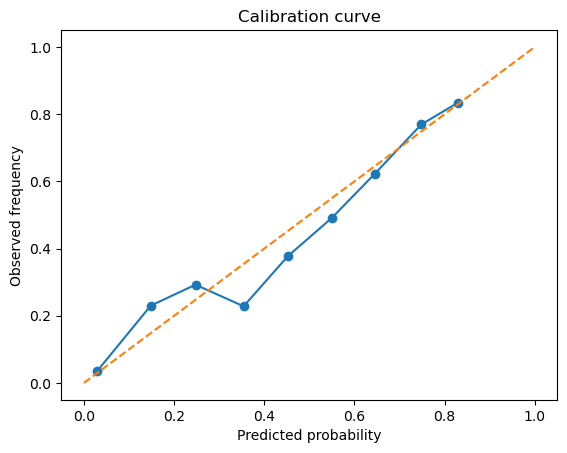

In [59]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, roc_auc_score, average_precision_score

# 3) calibrate using validation set
cal = CalibratedClassifierCV(clf, method="sigmoid", cv="prefit")
cal.fit(X_val, y_val)

# this would be the calibrated version
proba_cal = cal.predict_proba(X_test)[:, 1]

# 4) evaluate calibration + ranking on test
proba_cal = cal.predict_proba(X_test)[:, 1]
print("ROC-AUC:", roc_auc_score(y_test, proba_cal))
print("PR-AUC :", average_precision_score(y_test, proba_cal))
print("Brier  :", brier_score_loss(y_test, proba_cal))

import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

prob_true, prob_pred = calibration_curve(y_test, proba_cal, n_bins=10)

plt.figure()
plt.plot(prob_pred, prob_true, marker="o")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("Predicted probability")
plt.ylabel("Observed frequency")
plt.title("Calibration curve")
plt.show()


In [60]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, proba)

# thresholds has length n-1; precision/recall length n
thresholds_full = np.r_[thresholds, 1.0]

# quick view of a few candidate points
for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
    pred = (proba >= t).astype(int)
    p = (pred[y_test==1].sum() / max(pred.sum(), 1))  # precision (safe)
    r = (pred[y_test==1].sum() / (y_test==1).sum())   # recall
    print(f"t={t:.2f}  precision≈{p:.3f}  recall≈{r:.3f}")


t=0.20  precision≈0.389  recall≈0.952
t=0.30  precision≈0.415  recall≈0.893
t=0.40  precision≈0.447  recall≈0.818
t=0.50  precision≈0.476  recall≈0.733
t=0.60  precision≈0.542  recall≈0.658


In [69]:
from sklearn.metrics import confusion_matrix

calibrated = True # decide if we should use the calibrated probabilities or not
if calibrated:
    proba = proba_cal

C_FN = 1
C_FP = 1

costs = []
ts = np.linspace(0.05, 0.95, 91)
for t in ts:
    pred = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    costs.append(C_FN*fn + C_FP*fp)

best_t_cost = ts[int(np.argmin(costs))]
best_t_cost, min(costs)


(np.float64(0.5399999999999999), np.int64(136))

In [70]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, average_precision_score

def report_at_threshold(t):
    pred = (proba >= t).astype(int)
    print("threshold:", t)
    print("ROC-AUC:", roc_auc_score(y_test, proba))
    print("PR-AUC :", average_precision_score(y_test, proba))
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))

report_at_threshold(best_t_cost)


threshold: 0.5399999999999999
ROC-AUC: 0.8260690025395907
PR-AUC : 0.6349701385560417
[[475  43]
 [ 93  94]]
              precision    recall  f1-score   support

           0       0.84      0.92      0.87       518
           1       0.69      0.50      0.58       187

    accuracy                           0.81       705
   macro avg       0.76      0.71      0.73       705
weighted avg       0.80      0.81      0.80       705

